In [1]:
import numpy as np 
import pandas as pd 
from matplotlib import pyplot as plt 

In [2]:
# Read the selected_frames.parquet file
df = pd.read_parquet('selected_frames.parquet')

# Get total count
print(f"Total dataset count: {total_count}")

# Collect dE, Fmax, dS values
dE_values = df['dE'].to_numpy()
Fmax_values = df['Fmax'].to_numpy()
dSmax_values = df['dSmax'].to_numpy()

dE = np.concatenate(dE_values)
Fmax = np.concatenate(Fmax_values)
dSmax = np.concatenate(dSmax_values)

total_count = len(dSmax)

relaxed_count = (dSmax == 0).sum()

bin1_count = ((Fmax < 0.05)).sum()
bin1_percent = bin1_count / total_count
bin2_count = ((Fmax >= 0.05) & (Fmax < 0.10)).sum()
bin2_percent = bin2_count / total_count
bin3_count = ((Fmax >= 0.10) & (Fmax < 0.30)).sum()
bin3_percent = bin3_count / total_count
bin4_count = ((Fmax >= 0.30) & (Fmax < 0.60)).sum()
bin4_percent = bin4_count / total_count
total = bin1_count + bin2_count + bin3_count + bin4_count
print(f"Relaxed: {relaxed_count} \nBin 1: {bin1_count} ({bin1_percent}) \nBin 2: {bin2_count} ({bin2_percent}) \nBin 3: {bin3_count} ({bin3_percent}) \nBin 4: {bin4_count} ({bin4_percent}) \nTotal: {total}")

plt.figure()
bin1_dist = dSmax[Fmax < 0.05]
bins = np.arange(0, 0.20, 0.01)
plt.hist(bin1_dist, bins=bins)

plt.figure()
bin2_dist = dSmax[(Fmax >= 0.05) & (Fmax < 0.10)]
bins = np.arange(0, 0.20, 0.01)
plt.hist(bin2_dist, bins=bins)

plt.figure()
bin3_dist = dSmax[(Fmax >= 0.10) & (Fmax < 0.60)]
bins = np.arange(0, 0.60, 0.01)
plt.hist(bin3_dist, bins=bins)

plt.figure()
bin3_dist = dSmax
bins = np.arange(0, 0.60, 0.01)
plt.hist(dSmax, bins=bins)

NameError: name 'total_count' is not defined

(array([23539., 53426., 57501., 53033., 46771., 41326., 36513., 32564.,
        29453., 26669., 24160., 21834., 20074., 18504., 17033., 15774.,
        14619., 13374., 12398., 11598., 10735., 10111.,  9240.,  8636.,
         8293.,  7880.,  7429.,  7091.,  6759.,  6404.,  6031.,  5694.,
         5529.,  5159.,  5101.,  4828.,  4758.,  4519.,  4166.,  4226.,
         3991.,  3893.,  3729.,  3651.,  3576.,  3400.,  3231.,  3130.,
         3013.,  3032.,  3021.,  2912.,  2774.,  2659.,  2602.,  2559.,
         2570.,  2426.,  2398.]),
 array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
        0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
        0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
        0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
        0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5 , 0.51, 0.52, 0.53, 0.54,
        0.55, 0.56, 0.57, 0.58, 0.59]),
 <BarContainer object of 59 artists>)

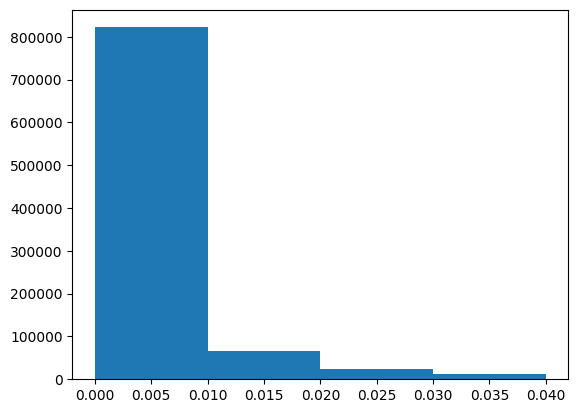

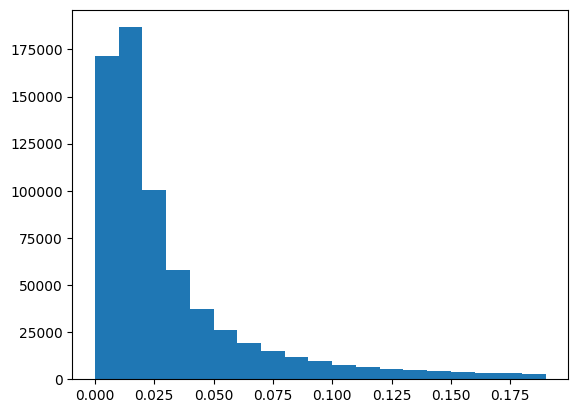

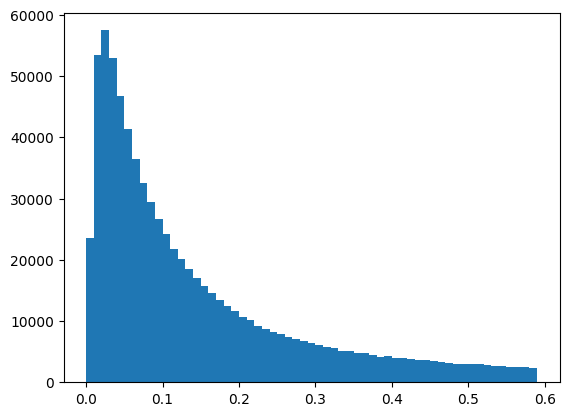

In [13]:
plt.figure()
bin1_dist = dE[Fmax < 0.05]
bins = np.arange(0, 0.05, 0.01)
plt.hist(bin1_dist, bins=bins)

plt.figure()
bin2_dist = dE[(Fmax >= 0.05) & (Fmax < 0.10)]
bins = np.arange(0, 0.20, 0.01)
plt.hist(bin2_dist, bins=bins)

plt.figure()
bin3_dist = dE[(Fmax >= 0.10) & (Fmax < 0.60)]
bins = np.arange(0, 0.60, 0.01)
plt.hist(bin3_dist, bins=bins)

In [5]:
# Collect dE, Fmax, dS values
dE_values = df['dE'].to_numpy()
Fmax_values = df['Fmax'].to_numpy()
dSmax_values = df['dSmax'].to_numpy()

count = 0 
count2 = 0
for idx in range(0, len(dSmax_values)):
    s = dSmax_values[idx]    
    diff = abs(s[:, None] - s[None, :])
    
    mask = ~np.eye(diff.shape[0], dtype=bool)
    
    hits = (diff < 0.025) & (diff != 0)
    hits = np.unique(hits)

    if hits.any():
        count += hits.sum()
        count2 += 1 if np.argmin(dSmax_values[idx]) != 0 else 0 
        
       
   
print(count, count2)

0 0
